# 1. Data Loading and Initial Overview

## 1.1 Importing Libraries

In [1]:
# data manipulation and numerical calculations
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# display settings
pd.set_option('display.max_columns',None)
print('Libraries are imported successfully')

Libraries are imported successfully


## 1.2 Loading the Dataset

In [2]:
# loading the dataset(car details v3)
df=pd.read_csv('../data/raw/Car details v3.csv')

# display the first 5 rows
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


## 1.3 Understanding the Dataset

In [3]:
#no.of rows and columns in the dataset
df.shape

(8128, 13)

In [4]:
# dataset information and datatypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 1.6 MB


# 2. Duplicate and Missing Value Analysis

## 2.1 Checking Missing Values

In [5]:
#no.of missing values in each column
df.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

## 2.2 Checking Duplicate Records

In [6]:
# for duplicate values
df.duplicated().sum()

np.int64(1202)

In [7]:
# display the duplicate records
df[df.duplicated()]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
291,Hyundai Grand i10 Sportz,2017,450000,35000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,82 bhp,114Nm@ 4000rpm,5.0
296,Maruti Swift VXI,2012,330000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,85.8 bhp,114Nm@ 4000rpm,5.0
370,Jaguar XE 2016-2019 2.0L Diesel Prestige,2017,2625000,9000,Diesel,Dealer,Automatic,First Owner,13.6 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
371,Lexus ES 300h,2019,5150000,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487 CC,214.56 bhp,202Nm@ 3600-5200rpm,5.0
372,Jaguar XF 2.0 Diesel Portfolio,2017,3200000,45000,Diesel,Dealer,Automatic,First Owner,19.33 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7987,Renault Captur 1.5 Diesel RXT,2018,1265000,12000,Diesel,Individual,Manual,First Owner,20.37 kmpl,1461 CC,108.45 bhp,240Nm@ 1750rpm,5.0
7988,Maruti Ciaz Alpha Diesel,2019,1025000,32000,Diesel,Individual,Manual,First Owner,28.09 kmpl,1248 CC,88.50 bhp,200Nm@ 1750rpm,5.0
8117,Maruti Swift Dzire VDI,2015,625000,50000,Diesel,Individual,Manual,First Owner,26.59 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [ ]:
# removing duplicates and creating a separate copy
df_clean=df.drop_duplicates().copy()

#new dataset size
df_clean.shape

(6926, 13)

## 2.3 Checking Missing Values After Removing Duplicates

In [9]:
#missing values after removing duplicates
df_clean.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
dtype: int64

In [10]:
#count of rows with atleast one missing value
df_clean.isnull().any(axis=1).sum()

np.int64(209)

In [11]:
#percentage of missing values in each column
(df_clean.isnull().sum()/len(df_clean))*100

name             0.000000
year             0.000000
selling_price    0.000000
km_driven        0.000000
fuel             0.000000
seller_type      0.000000
transmission     0.000000
owner            0.000000
mileage          3.003176
engine           3.003176
max_power        2.959861
torque           3.017615
seats            3.003176
dtype: float64

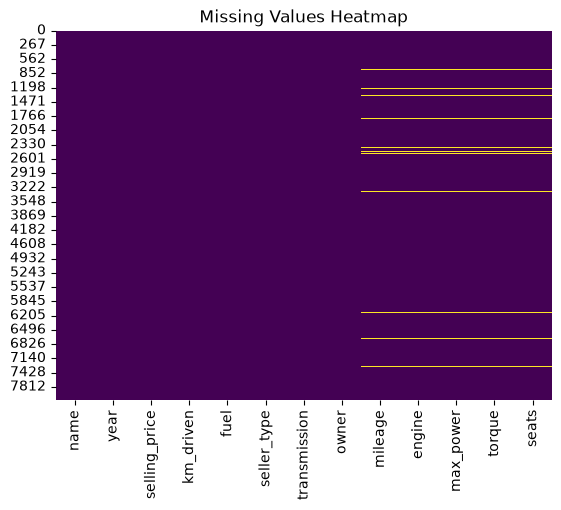

In [12]:
#visualizing the missing values
sns.heatmap(df_clean.isnull(),cbar=False,cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

In [13]:
# display the first 10 rows with missing values
df_clean[df_clean.isnull().any(axis=1)].head(10)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
13,Maruti Swift 1.3 VXi,2007,200000,80000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
31,Fiat Palio 1.2 ELX,2003,70000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
78,Tata Indica DLS,2003,50000,70000,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,NaN,NaN
87,Maruti Swift VDI BSIV W ABS,2015,475000,78000,Diesel,Dealer,Manual,First Owner,NaN,NaN,NaN,NaN,NaN
119,Maruti Swift VDI BSIV,2010,300000,120000,Diesel,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
138,BMW X1 sDrive 20D xLine,2017,2150000,27000,Diesel,Dealer,Automatic,First Owner,NaN,NaN,NaN,NaN,NaN
200,Toyota Etios GD,2012,235000,120000,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,NaN,NaN
206,Maruti Omni E 8 Str STD,2003,40000,90000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
228,Maruti Swift 1.3 VXi,2008,130000,120000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
252,Tata Indica DLS,2005,75000,110000,Diesel,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN


In [14]:
#count rows where all five columns are missing
df_clean[['mileage','engine','max_power','torque','seats']].isnull().all(axis=1).sum()

np.int64(205)

In [15]:
#identifying rows where some of the five columns are missing
missing=df_clean[['mileage','engine','max_power','torque','seats']].isnull()
df_clean[missing.any(axis=1) & ~missing.all(axis=1)]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
575,Maruti Alto K10 LXI,2011,204999,97500,Petrol,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN
1442,Maruti Swift Dzire VDI Optional,2017,589000,41232,Diesel,Dealer,Manual,First Owner,NaN,NaN,0,NaN,NaN
2549,Tata Indica Vista Quadrajet LS,2012,240000,70000,Diesel,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN
4933,Maruti Omni CNG,2000,80000,100000,CNG,Individual,Manual,Second Owner,10.9 km/kg,796 CC,bhp,NaN,8.0


# 3. Numerical Column Analysis

In [16]:
#statistical summary of numerical columns
df_clean.describe()

,year,selling_price,km_driven,seats
count,6926.000000,6.926000e+03,6.926000e+03,6718.000000
mean,2013.420300,5.172707e+05,7.399568e+04,5.434653
std,4.078286,5.197670e+05,5.835810e+04,0.984230
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.500000e+05,4.000000e+04,5.000000
50%,2014.000000,4.000000e+05,7.000000e+04,5.000000
75%,2017.000000,6.335000e+05,1.000000e+05,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


## 3.1 Year Analysis

In [17]:
# distinct years
print(df_clean['year'].value_counts().sort_index().to_string())

year
1983      1
1991      1
1994      3
1995      2
1996      3
1997     11
1998     10
1999     17
2000     20
2001      9
2002     26
2003     47
2004     60
2005     91
2006    123
2007    176
2008    205
2009    240
2010    380
2011    554
2012    604
2013    562
2014    581
2015    681
2016    693
2017    808
2018    608
2019    347
2020     63


In [18]:
#5 vehicles with oldest manufacturing years
df_clean.nsmallest(5,'year') 

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
316,Mahindra Willys CJ 3B 4X4,1983,300000,10000,Diesel,Individual,Manual,Third Owner,NaN,NaN,NaN,NaN,NaN
5322,Maruti Omni LPG STD BSIV,1991,55000,120000,LPG,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
1432,Mahindra Jeep CL 500 MDI,1994,120000,100000,Diesel,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
1474,Maruti 800 AC,1994,45000,60000,Petrol,Individual,Manual,First Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
4712,Ambassador Classic 2000 DSZ AC PS,1994,99000,100000,Diesel,Individual,Manual,Second Owner,12.8 kmpl,1995 CC,52 bhp,106Nm@ 2200rpm,5.0


In [19]:
# 5 vehicles with newest manufacturing years
df_clean.nlargest(5,'year')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
106,Ford Freestyle Titanium Petrol BSIV,2020,400000,5000,Petrol,Individual,Manual,Second Owner,19.0 kmpl,1194 CC,94.68 bhp,120Nm@ 4250rpm,5.0
115,Maruti Celerio VXI,2020,475000,13000,Petrol,Individual,Manual,First Owner,21.63 kmpl,998 CC,67.04 bhp,90Nm@ 3500rpm,5.0
196,Hyundai Elite i20 Sportz Plus BSIV,2020,720000,5000,Petrol,Individual,Manual,First Owner,18.6 kmpl,1197 CC,81.86 bhp,117nm@ 4000rpm,5.0
224,Hyundai Xcent 1.2 VTVT SX,2020,524000,32000,Petrol,Individual,Manual,First Owner,20.14 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
402,Maruti Eeco CNG 5 Seater AC,2020,409999,35000,CNG,Individual,Manual,First Owner,20.88 km/kg,1196 CC,61.7 bhp,85Nm@ 3000rpm,5.0


## 3.2 Selling Price Analysis

In [20]:
#checking for invalid prices
df_clean[df_clean['selling_price']<=0]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats


In [21]:
#5 vehicles with lowest selling prices
df_clean.nsmallest(5,'selling_price')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
5714,Maruti 800 AC,1997,29999,80000,Petrol,Individual,Manual,Third Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
2145,Maruti Zen LXI,2001,30000,10000,Petrol,Individual,Manual,First Owner,17.3 kmpl,993 CC,60 bhp,78Nm@ 4500rpm,5.0
6776,Hyundai Santro GLS I - Euro I,2000,30000,90000,Petrol,Individual,Manual,Third Owner,NaN,NaN,NaN,NaN,NaN
5965,Maruti 800 Std,2000,31000,56194,Petrol,Individual,Manual,Fourth & Above Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
1926,Maruti 800 Std,2004,31504,110000,Petrol,Individual,Manual,Third Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0


In [22]:
#5 vehicles with the highest selling prices
df_clean.nlargest(5,'selling_price')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
170,Volvo XC90 T8 Excellence BSIV,2017,10000000,30000,Petrol,Individual,Automatic,First Owner,42.0 kmpl,1969 CC,400 bhp,640Nm@ 1740rpm,4.0
2938,BMW X7 xDrive 30d DPE,2020,7200000,5000,Diesel,Individual,Automatic,First Owner,13.38 kmpl,2993 CC,265 bhp,620Nm@ 1500-2500rpm,7.0
4952,Audi A6 35 TFSI Matrix,2019,6523000,23600,Petrol,Dealer,Automatic,Test Drive Car,15.26 kmpl,1798 CC,187.74 bhp,320Nm@ 1400-4100rpm,5.0
4950,Audi A6 35 TFSI Matrix,2019,6223000,7800,Petrol,Dealer,Automatic,Test Drive Car,15.26 kmpl,1798 CC,187.74 bhp,320Nm@ 1400-4100rpm,5.0
136,Mercedes-Benz S-Class S 350 CDI,2017,6000000,37000,Diesel,Dealer,Automatic,First Owner,13.5 kmpl,2987 CC,254.79 bhp,620Nm@ 1600-2400rpm,5.0


In [23]:
#calculating IQR(Interquartile ranges) and identify potential outlier boundaries
q1=df_clean['selling_price'].quantile(0.25)
q3=df_clean['selling_price'].quantile(0.75)
IQR=q3-q1
print("q1:",q1)
print("q3:",q3)
print("IQR:",IQR)

lower_bound=q1-1.5*IQR
upper_bound=q3+1.5*IQR
print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

q1: 250000.0
q3: 633500.0
IQR: 383500.0
Lower Bound: -325250.0
Upper Bound: 1208750.0


In [24]:
#identify potential high price outliers
df_clean[df_clean['selling_price']>upper_bound]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
41,Jeep Compass 1.4 Limited Plus BSIV,2019,2100000,5000,Petrol,Individual,Automatic,First Owner,16.0 kmpl,1368 CC,160.77 bhp,250Nm@ 1750-2500rpm,5.0
47,Toyota Fortuner 4x4 MT,2014,1500000,77000,Diesel,Dealer,Manual,First Owner,12.55 kmpl,2982 CC,168.5 bhp,343Nm@ 1400-3400rpm,7.0
49,Mercedes-Benz B Class B180,2014,1450000,27800,Diesel,Dealer,Automatic,Second Owner,14.8 kmpl,2143 CC,120.7 bhp,200Nm@ 1250-4000rpm,5.0
55,Toyota Innova Crysta 2.8 ZX AT BSIV,2016,1650000,127700,Diesel,Dealer,Automatic,Second Owner,11.36 kmpl,2755 CC,171.5 bhp,360Nm@ 1200-3400rpm,7.0
57,Audi A6 2.0 TDI Technology,2013,1750000,33900,Diesel,Dealer,Automatic,Second Owner,17.68 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7951,Hyundai Creta 1.6 SX,2018,1220000,11000,Petrol,Individual,Manual,First Owner,15.8 kmpl,1591 CC,121.3 bhp,151Nm@ 4850rpm,5.0
7963,Renault Captur 1.5 Diesel RXT,2018,1265000,12000,Diesel,Individual,Manual,First Owner,20.37 kmpl,1461 CC,108.45 bhp,240Nm@ 1750rpm,5.0
7967,BMW 3 Series 320d Sedan,2011,1500000,84925,Diesel,Individual,Automatic,First Owner,16.07 kmpl,1995 CC,181 bhp,380Nm@ 1750-3000rpm,5.0
8058,Audi A3 40 TFSI Premium,2017,1689999,8000,Petrol,Dealer,Automatic,First Owner,16.6 kmpl,1798 CC,177.5 bhp,250Nm@ 1250-5000rpm,5.0


In [25]:
# percentage of potential high price outliers
outlier_percentage=(df_clean['selling_price']>upper_bound).sum()/len(df_clean)*100
print("outlier percentage:",outlier_percentage) 

outlier percentage: 4.735778226970835


## 3.3 Kilometers Driven Analysis

In [26]:
#checking for invalid values in km driven
df_clean[df_clean['km_driven']<=0]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats


In [27]:
#5 vehicles with lowest km driven
df_clean.nsmallest(5,'km_driven')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
7913,Maruti Eeco 5 STR With AC Plus HTR CNG,2011,209000,1,CNG,Individual,Manual,Fourth & Above Owner,15.1 km/kg,1196 CC,73 bhp,101Nm@ 3000rpm,5.0
399,Honda City i-VTEC CVT V,2018,1085000,1000,Petrol,Individual,Automatic,First Owner,18.0 kmpl,1497 CC,117.6 bhp,145Nm@ 4600rpm,5.0
2963,Maruti Swift AMT VXI,2020,654000,1000,Petrol,Individual,Automatic,First Owner,21.21 kmpl,1197 CC,81.80 bhp,113Nm@ 4200rpm,5.0
6638,Toyota Innova Crysta 2.4 ZX AT,2020,2300000,1000,Diesel,Individual,Automatic,First Owner,13.68 kmpl,2393 CC,147.51 bhp,360Nm@ 1400-2600rpm,7.0
7429,Maruti Swift LXI,2020,445000,1000,Petrol,Individual,Manual,First Owner,21.21 kmpl,1197 CC,81.80 bhp,113Nm@ 4200rpm,5.0


In [28]:
#5 vehicles with highest km driven
df_clean.nlargest(5,'km_driven')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
3486,Hyundai i20 Asta 1.2,2007,550000,2360457,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
1810,Mahindra XUV500 W6 2WD,2012,500000,1500000,Diesel,Individual,Manual,First Owner,15.1 kmpl,2179 CC,140 bhp,330Nm@ 1600-2800rpm,7.0
3508,Maruti Wagon R LXI Minor,2010,194000,577414,Petrol,Individual,Manual,Second Owner,18.9 kmpl,1061 CC,67 bhp,84Nm@ 3500rpm,5.0
3641,Maruti Wagon R VXI BS IV,2011,229999,500000,Petrol,Individual,Manual,Second Owner,18.9 kmpl,998 CC,67.1 bhp,90Nm@ 3500rpm,5.0
6673,Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII,2011,350000,500000,Diesel,Individual,Manual,Second Owner,12.99 kmpl,2494 CC,100.57 bhp,200Nm@ 1400-3400rpm,7.0


In [29]:
#identify potential outliers for km driven
q1_km=df_clean['km_driven'].quantile(0.25)
q3_km=df_clean['km_driven'].quantile(0.75)
IQR_km=q3_km-q1_km
lower_bound_km=q1_km-1.5*IQR_km
upper_bound_km=q3_km+1.5*IQR_km 
print("q1:",q1_km)
print("q3_km:",q3_km)
print("IQR:",IQR_km)
print("Lower bound:",lower_bound_km)
print("Upper bound:",upper_bound_km)

q1: 40000.0
q3_km: 100000.0
IQR: 60000.0
Lower bound: -50000.0
Upper bound: 190000.0


In [30]:
#potential high km driven outliers
df_clean[df_clean['km_driven']>upper_bound_km]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
272,Maruti Swift Dzire ZDi,2012,320000,193000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0
287,Mahindra Bolero DI DX 7 Seater,2007,210000,207890,Diesel,Individual,Manual,Second Owner,13.6 kmpl,2523 CC,63 bhp,180 Nm at 1440-1500rpm,7.0
394,Toyota Innova 2.5 G1 Diesel 8-seater,2005,250000,240000,Diesel,Individual,Manual,Third Owner,12.8 kmpl,2494 CC,102 bhp,20.4@ 1400-3400(kgm@ rpm),8.0
396,Hyundai Verna XXi ABS (Petrol),2009,340000,214000,Petrol,Individual,Manual,Second Owner,13.9 kmpl,1599 CC,103.2 bhp,"14.9@ 3,000(kgm@ rpm)",5.0
397,Hyundai Verna CRDi SX,2009,340000,214000,Diesel,Individual,Manual,Second Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8033,Hyundai Verna 1.6 SX,2012,450000,200000,Diesel,Individual,Manual,Second Owner,22.32 kmpl,1582 CC,126.32 bhp,259.8Nm@ 1900-2750rpm,5.0
8071,Toyota Innova 2.5 V Diesel 7-seater,2010,425000,200000,Diesel,Individual,Manual,Second Owner,12.8 kmpl,2494 CC,102 bhp,20.4@ 1400-3400(kgm@ rpm),7.0
8077,Toyota Innova 2.5 E 7 STR,2009,550000,250000,Diesel,Individual,Manual,First Owner,12.8 kmpl,2494 CC,102 bhp,20.4@ 1400-3400(kgm@ rpm),7.0
8095,Ford Figo Diesel Titanium,2012,260000,194000,Diesel,Individual,Manual,First Owner,20.0 kmpl,1399 CC,68 bhp,160Nm@ 2000rpm,5.0


In [31]:
#percentage of potential outliers
km_outlier_percentage=((df_clean['km_driven']>upper_bound_km).sum()/len(df_clean))*100
print('percentage of potential outliers for km driven:',km_outlier_percentage)

percentage of potential outliers for km driven: 2.411204158244297


## 3.4 Seats Analysis

In [32]:
#distinct seat values
df_clean['seats'].value_counts(dropna=False).sort_index()

seats
2.0        2
4.0      124
5.0     5254
6.0       57
7.0      966
8.0      222
9.0       74
10.0      18
14.0       1
NaN      208
Name: count, dtype: int64

In [33]:
#record that has 14 seats
df_clean[df_clean['seats']==14]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
4575,Tata Winger Deluxe - Flat Roof (Non-AC),2010,235000,50000,Diesel,Individual,Manual,First Owner,10.71 kmpl,1948 CC,90 bhp,190Nm@ 2000-3000rpm,14.0


In [34]:
# 5 vehicles with lowest seat counts
df_clean.nsmallest(5,'seats')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
5900,Mahindra Bolero Pik-Up FB 1.7T,2020,679000,5000,Diesel,Individual,Manual,First Owner,0.0 kmpl,2523 CC,70 bhp,200Nm@ 1400-2200rpm,2.0
6629,Mahindra Bolero Pik-Up CBC 1.7T,2019,722000,80000,Diesel,Individual,Manual,First Owner,0.0 kmpl,2523 CC,70 bhp,200Nm@ 1400-2200rpm,2.0
7,Maruti 800 DX BSII,2001,45000,5000,Petrol,Individual,Manual,Second Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
35,Maruti Alto 800 CNG LXI Optional,2019,330000,10000,CNG,Individual,Manual,Second Owner,33.44 km/kg,796 CC,40.3 bhp,60Nm@ 3500rpm,4.0
40,Maruti 800 Std,2012,150000,76000,Petrol,Individual,Manual,First Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0


In [35]:
#5 vehicles with highest seat counts
df_clean.nlargest(5,'seats')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
4575,Tata Winger Deluxe - Flat Roof (Non-AC),2010,235000,50000,Diesel,Individual,Manual,First Owner,10.71 kmpl,1948 CC,90 bhp,190Nm@ 2000-3000rpm,14.0
604,Tata Sumo CX 10 Str BSIV,2011,175000,20000,Diesel,Individual,Manual,First Owner,12.2 kmpl,1948 CC,68 bhp,"115@ 2,500(kgm@ rpm)",10.0
795,Chevrolet Tavera Neo 3 LS 10 Str,2016,409999,60000,Diesel,Individual,Manual,Second Owner,12.2 kmpl,1994 CC,105.3 bhp,263.7Nm@ 2500rpm,10.0
2086,Tata Sumo EX 10/7 Str BSIII,2012,200000,67500,Diesel,Individual,Manual,First Owner,12.2 kmpl,1948 CC,68 bhp,"115@ 2,500(kgm@ rpm)",10.0
2331,Chevrolet Tavera Neo 3 10 Seats BSIII,2014,600000,110000,Diesel,Individual,Manual,First Owner,13.58 kmpl,2499 CC,72.4 bhp,171Nm@ 1800rpm,10.0


# 4. Categorical Column Analysis

In [36]:
#displaying unique values in categorical columns
categorical_columns=['fuel','seller_type','transmission','owner']
for col in categorical_columns:
    print(f"\n{col}:")
    print(df_clean[col].value_counts())



fuel:
fuel
Diesel    3755
Petrol    3077
CNG         56
LPG         38
Name: count, dtype: int64

seller_type:
seller_type
Individual          6218
Dealer               681
Trustmark Dealer      27
Name: count, dtype: int64

transmission:
transmission
Manual       6342
Automatic     584
Name: count, dtype: int64

owner:
owner
First Owner             4242
Second Owner            1974
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5
Name: count, dtype: int64


In [37]:
#displaying all owner categories
print(df_clean['owner'].value_counts().to_string())

owner
First Owner             4242
Second Owner            1974
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5


# 5. Mixed Data Type Columns Analysis

## 5.1 Mileage Analysis

In [38]:
#distinct mileage values
df_clean['mileage'].value_counts(dropna=False).to_string()

'mileage\n18.9 kmpl      210\nNaN            208\n19.7 kmpl      168\n18.6 kmpl      150\n21.1 kmpl      146\n17.0 kmpl      124\n15.96 kmpl     108\n16.1 kmpl      106\n17.8 kmpl       95\n12.8 kmpl       88\n15.1 kmpl       85\n28.4 kmpl       85\n20.0 kmpl       83\n20.51 kmpl      83\n22.74 kmpl      80\n22.54 kmpl      76\n24.3 kmpl       73\n23.0 kmpl       71\n20.36 kmpl      71\n22.32 kmpl      71\n12.99 kmpl      70\n23.4 kmpl       65\n19.3 kmpl       65\n18.5 kmpl       65\n20.3 kmpl       64\n16.8 kmpl       62\n23.95 kmpl      62\n20.77 kmpl      61\n16.0 kmpl       60\n15.4 kmpl       60\n26.59 kmpl      58\n25.17 kmpl      58\n18.2 kmpl       56\n14.0 kmpl       56\n25.2 kmpl       56\n22.9 kmpl       55\n24.7 kmpl       52\n13.6 kmpl       52\n18.49 kmpl      52\n23.84 kmpl      50\n19.81 kmpl      49\n19.0 kmpl       49\n22.0 kmpl       48\n18.0 kmpl       48\n19.1 kmpl       47\n17.5 kmpl       47\n24.0 kmpl       46\n17.3 kmpl       45\n12.05 kmpl      45\n20.4 kmpl 

In [39]:
#records with zero mileage
df_clean[df_clean['mileage']=='0.0 kmpl']

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
644,Tata Indica Vista Aura Safire Anniversary Edition,2009,135000,28900,Petrol,Individual,Manual,Second Owner,0.0 kmpl,1172 CC,65 bhp,"9.8@ 3,000(kgm@ rpm)",5.0
785,Hyundai Santro Xing GL,2009,120000,90000,Petrol,Individual,Manual,Second Owner,0.0 kmpl,1086 CC,62 bhp,96.1Nm@ 3000rpm,5.0
1649,Hyundai Santro Xing GL,2008,105000,128000,Petrol,Individual,Manual,First Owner,0.0 kmpl,1086 CC,62 bhp,96.1Nm@ 3000rpm,5.0
1676,Mercedes-Benz M-Class ML 350 4Matic,2011,1700000,110000,Diesel,Individual,Automatic,Third Owner,0.0 kmpl,2987 CC,165 bhp,510@ 1600-2400,5.0
2137,Land Rover Freelander 2 TD4 HSE,2013,1650000,64788,Diesel,Dealer,Automatic,First Owner,0.0 kmpl,2179 CC,115 bhp,400 Nm /2000 rpm,5.0
2366,Hyundai Santro Xing (Non-AC),2010,110000,80000,Petrol,Individual,Manual,Second Owner,0.0 kmpl,1086 CC,62.1 bhp,96.1Nm@ 3000rpm,5.0
2725,Hyundai Santro Xing (Non-AC),2013,184000,15000,Petrol,Individual,Manual,First Owner,0.0 kmpl,1086 CC,62.1 bhp,96.1Nm@ 3000rpm,5.0
5276,Hyundai Santro Xing GL,2008,175000,40000,Petrol,Individual,Manual,First Owner,0.0 kmpl,1086 CC,62 bhp,96.1Nm@ 3000rpm,5.0
5843,Volkswagen Polo GT TSI BSIV,2014,574000,28080,Petrol,Dealer,Automatic,First Owner,0.0 kmpl,1197 CC,103.25 bhp,175nm@ 1500-4100rpm,5.0
5846,Volkswagen Polo GT TSI BSIV,2014,575000,28100,Petrol,Dealer,Automatic,First Owner,0.0 kmpl,1197 CC,103.25 bhp,175nm@ 1500-4100rpm,5.0


In [40]:
#count zero mileage records
(df_clean['mileage']=='0.0 kmpl').sum()

np.int64(15)

In [41]:
#vehicles with 42.0kmpl mileage
df_clean[df_clean['mileage']=='42.0 kmpl']

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
170,Volvo XC90 T8 Excellence BSIV,2017,10000000,30000,Petrol,Individual,Automatic,First Owner,42.0 kmpl,1969 CC,400 bhp,640Nm@ 1740rpm,4.0


In [42]:
#display the lowest mileage values(sorted alphabetically)
df_clean['mileage'].value_counts().sort_index().head(10)

mileage
0.0 kmpl      15
10.0 kmpl      2
10.1 kmpl      2
10.5 kmpl     17
10.71 kmpl     1
10.75 kmpl     2
10.8 kmpl      1
10.9 km/kg     3
10.9 kmpl      1
10.91 kmpl     4
Name: count, dtype: int64

In [43]:
#records with lowest mileage value after 0
df_clean[df_clean['mileage']=='10.0 kmpl']

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
4393,Mercedes-Benz E-Class E 220 CDI Avantgarde,2011,1600000,74000,Diesel,Dealer,Automatic,First Owner,10.0 kmpl,2148 CC,170 bhp,400Nm@ 1400-2800rpm,5.0
5506,Mercedes-Benz E-Class E 220 CDI Avantgarde,2013,1925000,91500,Diesel,Dealer,Automatic,First Owner,10.0 kmpl,2148 CC,170 bhp,400Nm@ 1400-2800rpm,5.0


## 5.2 Engine Analysis

In [44]:
#unique engine values
df_clean['engine'].value_counts(dropna=False).to_string()

'engine\n1248 CC    907\n1197 CC    698\n796 CC     421\n998 CC     398\n2179 CC    339\n1498 CC    336\n1396 CC    281\nNaN        208\n1199 CC    192\n2523 CC    183\n1461 CC    169\n1198 CC    163\n1497 CC    161\n2494 CC    151\n1582 CC    143\n1493 CC    132\n1086 CC    129\n1399 CC    116\n814 CC     111\n1405 CC    108\n1196 CC     86\n799 CC      71\n1598 CC     70\n999 CC      69\n1061 CC     57\n1364 CC     51\n1120 CC     49\n995 CC      42\n1193 CC     41\n2498 CC     41\n1298 CC     40\n1591 CC     39\n1373 CC     39\n1968 CC     37\n1995 CC     35\n936 CC      34\n1186 CC     31\n2499 CC     31\n1991 CC     30\n1997 CC     28\n2982 CC     27\n993 CC      26\n2755 CC     25\n624 CC      25\n2393 CC     24\n2143 CC     22\n1956 CC     22\n2489 CC     22\n1495 CC     20\n1586 CC     20\n2956 CC     19\n1047 CC     18\n1798 CC     17\n1499 CC     17\n1368 CC     16\n1599 CC     16\n1496 CC     16\n2354 CC     14\n2609 CC     14\n1896 CC     14\n1998 CC     13\n1194 CC     13\

## 5.3 Maximum Power Analysis

In [45]:
# distinct max power values
df_clean['max_power'].value_counts(dropna=False).to_string()

'max_power\n74 bhp         324\nNaN            205\n88.5 bhp       177\n46.3 bhp       158\n67 bhp         152\n67.1 bhp       141\n67.04 bhp      136\n81.80 bhp      136\n70 bhp         134\n47.3 bhp       131\n62.1 bhp       130\n120 bhp        126\n81.86 bhp      123\n73.9 bhp       123\n68 bhp         120\n140 bhp        120\n98.6 bhp       111\n55.2 bhp       111\n75 bhp         104\n82 bhp          97\n88.7 bhp        97\n63 bhp          96\n88.73 bhp       91\n37 bhp          88\n81.83 bhp       85\n67.05 bhp       83\n100 bhp         83\n78.9 bhp        81\n88.76 bhp       81\n102 bhp         78\n90 bhp          72\n68.05 bhp       71\n69 bhp          69\n126.2 bhp       67\n85.8 bhp        67\n88.8 bhp        63\n126.32 bhp      60\n84 bhp          60\n74.02 bhp       60\n53.3 bhp        58\n100.6 bhp       54\n83.8 bhp        53\n138.1 bhp       52\n108.5 bhp       49\n103.6 bhp       48\n86.8 bhp        43\n108.45 bhp      42\n80 bhp          42\n62 bhp          42\n83.1 bhp

In [46]:
#records with zero or invalid maximum power values
df_clean[df_clean['max_power'].str.strip().isin(['0','bhp'])]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
575,Maruti Alto K10 LXI,2011,204999,97500,Petrol,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN
1442,Maruti Swift Dzire VDI Optional,2017,589000,41232,Diesel,Dealer,Manual,First Owner,NaN,NaN,0,NaN,NaN
2549,Tata Indica Vista Quadrajet LS,2012,240000,70000,Diesel,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN
4933,Maruti Omni CNG,2000,80000,100000,CNG,Individual,Manual,Second Owner,10.9 km/kg,796 CC,bhp,NaN,8.0


## 5.4 Torque Analysis

In [47]:
#unique torque values
df_clean['torque'].value_counts(dropna=False).to_string()

'torque\n190Nm@ 2000rpm                 472\n200Nm@ 1750rpm                 398\n90Nm@ 3500rpm                  353\nNaN                            209\n62Nm@ 3000rpm                  160\n114Nm@ 4000rpm                 156\n113Nm@ 4200rpm                 139\n160Nm@ 2000rpm                 131\n69Nm@ 3500rpm                  131\n330Nm@ 1600-2800rpm            114\n74.5Nm@ 4000rpm                111\n59Nm@ 2500rpm                  107\n195Nm@ 1400-2200rpm             94\n219.7Nm@ 1500-2750rpm           88\n114.7Nm@ 4000rpm                85\n20.4@ 1400-3400(kgm@ rpm)       77\n290Nm@ 1800-2800rpm             74\n114Nm@ 3500rpm                  71\n250Nm@ 1500-2500rpm             70\n72Nm@ 4386rpm                   70\n259.9Nm@ 1900-2750rpm           68\n115Nm@ 4000rpm                  66\n113.75nm@ 4000rpm               65\n320Nm@ 1700-2700rpm             64\n140Nm@ 1800-3000rpm             61\n205Nm@ 1750-3250rpm             60\n259.8Nm@ 1900-2750rpm           60\n240Nm@ 1600-2800rpm

In [48]:
#checking unusual torque values
unusual_torque=['789Nm@ 2250rpm','190@ 21,800(kgm@ rpm)','400Nm@ 175-2750rpm','510@ 1600-2400']
df_clean[df_clean['torque'].isin(unusual_torque)]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
951,Maruti Zen D,2003,85000,120000,Diesel,Individual,Manual,Third Owner,20.8 kmpl,1527 CC,58 bhp,789Nm@ 2250rpm,5.0
1676,Mercedes-Benz M-Class ML 350 4Matic,2011,1700000,110000,Diesel,Individual,Automatic,Third Owner,0.0 kmpl,2987 CC,165 bhp,510@ 1600-2400,5.0
4384,Hyundai Tucson 2.0 e-VGT 2WD AT GLS,2016,1950000,45000,Diesel,Dealer,Automatic,Second Owner,16.38 kmpl,1995 CC,183 bhp,400Nm@ 175-2750rpm,5.0
4720,Maruti Zen D,2002,120000,60000,Diesel,Individual,Manual,Second Owner,20.8 kmpl,1527 CC,58 bhp,789Nm@ 2250rpm,5.0
5143,Maruti Zen D,2006,80000,110000,Diesel,Individual,Manual,Second Owner,20.8 kmpl,1527 CC,58 bhp,789Nm@ 2250rpm,5.0
5415,Tata Sumo EX TC,2005,225000,188000,Diesel,Individual,Manual,First Owner,12.3 kmpl,1948 CC,90 bhp,"190@ 21,800(kgm@ rpm)",7.0


# 6. Summary of Data Understanding

I explored the Used Car dataset which contains 4 csv files. Among them, I selected Car details v3.csv as the primary dataset because it contains the vehicle specifications needed for this project.

- This dataset initially contains 8,128 records and 13 columns.

- Missing values before removing duplicates: 1,100
- Duplicate records: 1,202
- Records after removing duplicates: 6,926
- Missing values after removing duplicates: 1,038
- Records containing missing values: 209

During the analysis, I identified some unusual values in mileage, maximum power and torque that need further checking and cleaning.